# Chapter 43: Risk, Return, Diversification, and Portfolio Choice

This notebook reruns four worked examples from the chapter: the CAPM hurdle rate, myopic loss aversion, the volatility cost of home bias, and risk pooling with correlated losses. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def capm(rf, beta, rm):
    """capital-asset-pricing-model: E[R_i] = R_f + beta_i (E[R_M] - R_f), in percent.

    Book (ch043): capm(2.5, 1.3, 8.5) = 10.3; capm(2.5, 0.8, 8.5) = 7.3; premium 6.
    """
    return rf + beta * (rm - rf)


def two_asset_variance(w, s1, s2, rho):
    """home-bias-puzzle: w^2 s1^2 + (1-w)^2 s2^2 + 2 w (1-w) rho s1 s2.

    Book (ch043): (0.75, 0.22, 0.16, 0.30) -> 0.032785; w = 0.10 -> 0.0231208.
    """
    return w * w * s1 * s1 + (1 - w) ** 2 * s2 * s2 + 2 * w * (1 - w) * rho * s1 * s2


def pooled_loss_sd(n, p, loss, rho=0.0):
    """insurance-risk-pooling: average-loss SD of n stores with equal pairwise correlation rho.

    Var(avg) = p(1-p)loss^2 (rho + (1-rho)/n). Book (ch043): n=225, p=0.04, loss=5,000:
    individual variance 960,000, SD 979.80, total SD 14,696.94, average SD 65.32 (rho 0),
    variance 99,840 and SD 315.97 (rho 0.10). Returns a dict.
    """
    var1 = p * (1 - p) * loss * loss
    var_avg = var1 * (rho + (1 - rho) / n)
    return {"expected": p * loss, "var_ind": var1, "sd_ind": math.sqrt(var1),
            "total_sd_indep": math.sqrt(n * var1), "var_avg": var_avg, "sd_avg": math.sqrt(var_avg),
            "floor_sd": math.sqrt(rho * var1)}


plt.rcParams.update(HOUSE_RC)


finance = SimpleNamespace(capm=capm, two_asset_variance=two_asset_variance, pooled_loss_sd=pooled_loss_sd)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'capital-asset-pricing-model': {'rf': 2.5,
                                 'rm': 8.5,
                                 'premium': 6,
                                 'beta': 1.3,
                                 'required': 10.3,
                                 'beta_2': 0.8,
                                 'required_2': 7.3,
                                 'drop': 3},
 'myopic-loss-aversion': {'gain': 15,
                          'loss': 10,
                          'p': 0.5,
                          'lam': 2,
                          'per_period': -2.5,
                          'two_looks': -5,
                          'aggregated': 0,
                          'totals': {30: 0.25, 5: 0.5, -20: 0.25}},
 'home-bias-puzzle': {'s_dom': 0.22,
                      's_for': 0.16,
                      'rho': 0.3,
                      'w': 0.75,
                      'w_world': 0.1,
                      'portfolio': 200000,
                      'domestic_dollars': 150000,
                      'benchmark_dollars': 20000,
                      'gap': 0.65,
                      'var': 0.032785,
                      'vol_pct': 18.11,
                      'var_world': 0.0231208,
                      'vol_world_pct': 15.21},
 'insurance-risk-pooling': {'n': 225,
                            'p': 0.04,
                            'loss': 5000,
                            'expected': 200,
                            'var_ind': 960000,
                            'sd_ind': 979.8,
                            'total_expected': 45000,
                            'total_sd': 14696.94,
                            'sd_avg': 65.32,
                            'admin': 25,
                            'capital': 15,
                            'premium': 240,
                            'rho': 0.1,
                            'var_avg_rho': 99840,
                            'sd_avg_rho': 315.97},
 'constructed': {'capital-asset-pricing-model': {'betas': [0.5, 1.8], 'rms': [6.5, 10.5]},
                 'myopic-loss-aversion': {'lams': [1, 1.5, 2.5]},
                 'home-bias-puzzle': {'ws': [0.4, 1.0], 'rhos': [0.0, 0.6]},
                 'insurance-risk-pooling': {'ns': [25, 100, 900], 'rhos': [0.05]}}}


def _exact(x, digits=8):
    """Decimal string with trailing zeros dropped (the terms here are exact at 8 decimals)."""
    s = num(x, digits, comma=False)
    return s.rstrip("0").rstrip(".") if "." in s else s


def capm_picture(beta=1.3, rm=8.5):
    rf = 2.5
    req = finance.capm(rf, beta, rm)
    bench = finance.capm(rf, 0.8, rm)
    prem = rm - rf
    bs = np.linspace(0, 2, 100)
    fig, ax = new_figure()
    ax.plot(bs, [finance.capm(rf, b, rm) for b in bs], color=PALETTE["teal"], linewidth=2.2,
            label=f"security market line, market return {num(rm, 1)}%")
    hline(ax, rf, f"risk-free {num(rf, 1)}%", col="grey", x_frac=0.55)
    mark(ax, 1, rm, f"market ({num(rm, 1)}%)", col="ink", dx=8, dy=-12, va="top")
    mark(ax, beta, req, f"project: {num(req, 1)}%", col="navy", dx=-8, dy=8, ha="right")
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 22)
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlabel("Beta")
    ax.set_ylabel("Expected return (%)")
    diff = req - bench
    metrics = {"Market premium": f"{num(prem, 1)}%", "Required return": f"{num(req, 1)}%",
               "Benchmark at beta 0.8": f"{num(bench, 1)}%", "Change versus beta 0.8": f"{plus(diff, 1)} points"}
    interp = (f"The market premium is {num(rm, 1)} - 2.5 = {num(prem, 1)}%. CAPM gives 2.5 + {num(beta, 1)} x "
              f"{num(prem, 1)} = 2.5 + {num(beta * prem, 2)} = {num(req, 2)}%. Against the beta 0.8 benchmark of "
              f"{num(bench, 2)}% the hurdle is "
              + ("the same, 0.00 points apart." if abs(diff) < 1e-9 else
                 f"{num(abs(diff), 2)} points {'higher' if diff > 0 else 'lower'}."))
    steps = [f"Premium = {num(rm, 1)} - 2.5 = {num(prem, 1)}",
             f"E[R] = 2.5 + {num(beta, 1)} x {num(prem, 1)} = 2.5 + {num(beta * prem, 2)} = {num(req, 2)}%",
             f"Benchmark = 2.5 + 0.8 x {num(prem, 1)} = {num(bench, 2)}%",
             f"Change = {num(req, 2)} - {num(bench, 2)} = {plus(diff, 2)} points"]
    alt = (f"Security market line from 2.5% at beta 0 through the market at beta 1 and {num(rm, 1)}%. "
           f"The project at beta {num(beta, 1)} requires {num(req, 1)}%.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def framed_values(lam, gain=15, loss=10, p=0.5):
    """Experienced value per look, over two separate looks, and with the two periods aggregated."""
    per = p * gain + (1 - p) * lam * (-loss)
    totals = {2 * gain: p * p, gain - loss: 2 * p * (1 - p), -2 * loss: (1 - p) ** 2}
    agg = sum(pr * (x if x >= 0 else lam * x) for x, pr in totals.items())
    return {"per_look": per, "two_looks": 2 * per, "aggregated": agg, "totals": totals}


def loss_picture(lam=2, frame="separate"):
    r = framed_values(lam)
    fig, ax = new_figure()
    if frame == "separate":
        names, probs, vals = ["gain 15", "loss 10"], [0.5, 0.5], [15, -10 * lam]
        value, vlabel = r["per_look"], "value per look"
    else:
        names, probs, vals = ["total 30", "total 5", "total -20"], [0.25, 0.5, 0.25], [30, 5, -20 * lam]
        value, vlabel = r["aggregated"], "value of the two periods together"
    cols = [PALETTE["teal"] if v >= 0 else PALETTE["terracotta"] for v in vals]
    xs = range(len(names))
    ax.bar(xs, vals, color=cols, width=0.6)
    for x, v, pr in zip(xs, vals, probs):
        ax.annotate(f"{num(v, 1)}, prob {num(pr, 2)}", (x, v), xytext=(0, 4 if v >= 0 else -4),
                    textcoords="offset points", ha="center", va="bottom" if v >= 0 else "top", fontsize=10.5)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.axhline(value, color=PALETTE["navy"], linestyle="dashed", linewidth=1.4, label=f"{vlabel}: {num(value, 2)}")
    ax.legend(loc="upper right", frameon=False)
    ax.set_xticks(list(xs))
    ax.set_xticklabels(names)
    ax.set_xlim(-0.6, len(names) - 0.4)
    ax.set_ylim(-60, 42)
    ax.set_xlabel("Outcome as coded")
    ax.set_ylabel("Experienced value (points)")
    winner, tie = tie_or_winner("aggregated", r["aggregated"], "separate", r["two_looks"])
    better = ("Both framings give the same value." if tie else
              f"The {winner} framing feels better by {num(abs(r['aggregated'] - r['two_looks']), 2)} points.")
    metrics = {"Value per look": num(r["per_look"], 2), "Two separate looks": num(r["two_looks"], 2),
               "Two periods aggregated": num(r["aggregated"], 2), "Framing that feels better": "tie" if tie else winner}
    common = (f"Separate: 0.5(15) + 0.5[{num(lam, 1)}(-10)] = 7.5 - {num(5 * lam, 2)} = {num(r['per_look'], 2)} per "
              f"look, {num(r['two_looks'], 2)} over two looks. Aggregated: 0.25(30) + 0.50(5) + 0.25[{num(lam, 1)}(-20)] "
              f"= 7.5 + 2.5 - {num(5 * lam, 2)} = {num(r['aggregated'], 2)}.")
    interp = (f"{common} {better} The payoffs are identical; only the evaluation boundary changed.")
    steps = [f"Per look = 7.5 - 0.5 x {num(lam, 1)} x 10 = {num(r['per_look'], 2)}",
             f"Two looks = 2 x {num(r['per_look'], 2)} = {num(r['two_looks'], 2)}",
             f"Aggregated = 7.5 + 2.5 - 0.25 x {num(lam, 1)} x 20 = {num(r['aggregated'], 2)}"]
    alt = (f"Bars of experienced value for the {'per period' if frame == 'separate' else 'two-period total'} outcomes "
           f"with loss weight {num(lam, 1)}; the {vlabel} is {num(value, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def home_picture(w=0.75, rho=0.30):
    s1, s2 = 0.22, 0.16
    var = finance.two_asset_variance(w, s1, s2, rho)
    var0 = finance.two_asset_variance(0.10, s1, s2, rho)
    vol, vol0 = 100 * math.sqrt(var), 100 * math.sqrt(var0)
    gap = round(vol, 2) - round(vol0, 2)
    ws = np.linspace(0, 1, 200)
    fig, ax = new_figure()
    ax.plot(ws, [100 * math.sqrt(finance.two_asset_variance(x, s1, s2, rho)) for x in ws], color=PALETTE["teal"],
            linewidth=2.2, label=f"portfolio volatility, correlation {num(rho, 2)}")
    vline(ax, 0.10, "world weight 0.10", col="grey", y_frac=0.06)
    mark(ax, 0.10, vol0, f"{num(vol0, 2)}%", col="gold", dx=8, dy=-10, va="top")
    if abs(w - 0.10) > 1e-9:
        mark(ax, w, vol, f"w = {num(w, 2)}: {num(vol, 2)}%", col="navy", dx=(8 if w < 0.5 else -8), dy=-12,
             ha=("left" if w < 0.5 else "right"), va="top")
    ax.set_xlim(0, 1)
    ax.set_ylim(10, 24)
    ax.legend(loc="upper center", frameon=False)
    ax.set_xlabel("Domestic weight w")
    ax.set_ylabel("Volatility (%)")
    t1, t2, t3 = w * w * s1 * s1, (1 - w) ** 2 * s2 * s2, 2 * w * (1 - w) * rho * s1 * s2
    metrics = {"Portfolio variance": _exact(var), "Volatility": f"{num(vol, 2)}%",
               "Volatility at world weight": f"{num(vol0, 2)}%", "Gap versus world weight": f"{num(gap, 2)} points",
               "Domestic dollars": money(w * 200_000, 0)}
    if abs(w - 0.10) < 1e-9:
        tail = "This is the world weight itself, so there is no gap."
    else:
        tail = (f"Volatility is {num(vol, 2)}% against {num(vol0, 2)}% at the world weight, a gap of "
                f"{num(vol, 2)} - {num(vol0, 2)} = {num(gap, 2)} points with the same expected return.")
    interp = (f"Variance = {num(w, 2)}^2(0.0484) + {num(1 - w, 2)}^2(0.0256) + 2({num(w, 2)})({num(1 - w, 2)})"
              f"({num(rho, 2)})(0.0352) = {_exact(t1)} + {_exact(t2)} + {_exact(t3)} = {_exact(var)}. {tail}")
    steps = [f"w^2 x 0.22^2 = {num(w, 2)}^2 x 0.0484 = {_exact(t1)}",
             f"(1 - w)^2 x 0.16^2 = {num(1 - w, 2)}^2 x 0.0256 = {_exact(t2)}",
             f"2w(1 - w)(rho)(0.22)(0.16) = {_exact(t3)}",
             f"Variance = {_exact(var)}, volatility = sqrt({_exact(var)}) = {num(vol, 2)}%",
             f"Domestic dollars = {num(w, 2)} x 200,000 = {money(w * 200_000, 0)}"]
    alt = (f"Volatility against domestic weight for correlation {num(rho, 2)}. At w = {num(w, 2)} volatility is "
           f"{num(vol, 2)}%; at the world weight 0.10 it is {num(vol0, 2)}%.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def pool_picture(n=225, rho=0.0):
    r = finance.pooled_loss_sd(n, 0.04, 5_000, rho)
    ns = np.logspace(0, np.log10(2_000), 200)
    fig, ax = new_figure()
    ax.plot(ns, [finance.pooled_loss_sd(k, 0.04, 5_000, rho)["sd_avg"] for k in ns], color=PALETTE["teal"],
            linewidth=2.2, label=f"average-loss SD, correlation {num(rho, 2)}")
    if rho > 0:
        hline(ax, r["floor_sd"], f"floor sqrt({num(rho, 2)}) x 979.80 = {num(r['floor_sd'], 2)}", col="terracotta",
              x_frac=0.03)
    mark(ax, n, r["sd_avg"], f"{num(n, 0)} stores: {money(r['sd_avg'], 2)}", col="navy",
         dx=(8 if n < 500 else -8), dy=8, ha=("left" if n < 500 else "right"))
    ax.set_xscale("log")
    ax.set_xlim(1, 2_000)
    ax.set_ylim(0, 1_100)
    ax.legend(loc="upper right", frameon=False)
    ax.set_xlabel("Stores in pool (log scale)")
    ax.set_ylabel("SD of average loss per store ($)")
    metrics = {"Expected loss per store": money(r["expected"], 0), "Individual SD": money(r["sd_ind"], 2),
               "Average-loss SD": money(r["sd_avg"], 2), "Floor as the pool grows": money(r["floor_sd"], 2),
               "Illustrative premium": money(240, 0)}
    interp = (f"Expected loss is 0.04(5,000) = 200 and individual variance 0.04(0.96)(5,000)^2 = 960,000, an SD of "
              f"979.80. Average-loss variance is 960,000({num(rho, 2)} + {num(1 - rho, 2)}/{num(n, 0)}) = "
              f"{num(r['var_avg'], 2)}, so the SD is {num(r['sd_avg'], 2)} dollars. "
              + (f"Independent losses shrink it by sqrt({num(n, 0)}) = {num(math.sqrt(n), 2)}." if rho == 0 else
                 f"However large the pool, it cannot fall below {num(r['floor_sd'], 2)}.")
              + " The premium of 240 is 200 of expected claims plus 25 + 15 for administration and capital.")
    steps = ["Expected loss = 0.04 x 5,000 = 200", "Individual variance = 0.04 x 0.96 x 5,000^2 = 960,000",
             f"Average variance = 960,000 x ({num(rho, 2)} + {num(1 - rho, 2)}/{num(n, 0)}) = {num(r['var_avg'], 2)}",
             f"Average SD = sqrt({num(r['var_avg'], 2)}) = {num(r['sd_avg'], 2)}",
             "Premium = 200 + 25 + 15 = 240"]
    alt = (f"Standard deviation of the average loss per store against pool size on a log scale, correlation "
           f"{num(rho, 2)}. At {num(n, 0)} stores it is {num(r['sd_avg'], 2)} dollars.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Capital asset pricing model

Risk-free return 2.5%, expected market return 8.5%, project beta 1.3 (0.8 after the redesign).

$$E[R_i]=R_f+\beta_i\big(E[R_M]-R_f\big), \qquad E[R]=2.5\%+1.3(6\%)=10.3\%$$

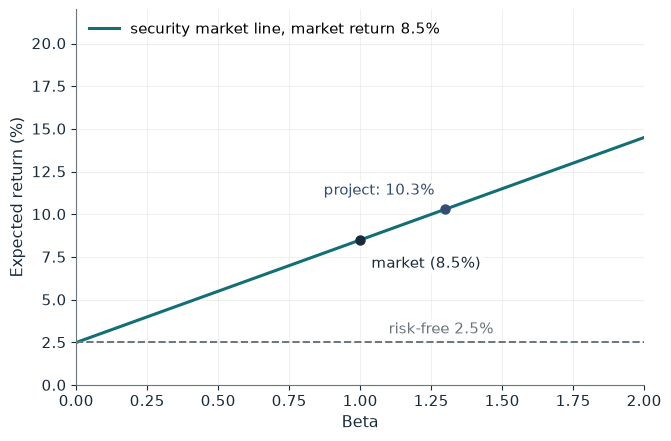

Market premium          6.0%
Required return         10.3%
Benchmark at beta 0.8   7.3%
Change versus beta 0.8  +3.0 points

Worked steps:
  1. Premium = 8.5 - 2.5 = 6.0
  2. E[R] = 2.5 + 1.3 x 6.0 = 2.5 + 7.80 = 10.30%
  3. Benchmark = 2.5 + 0.8 x 6.0 = 7.30%
  4. Change = 10.30 - 7.30 = +3.00 points

The market premium is 8.5 - 2.5 = 6.0%. CAPM gives 2.5 + 1.3 x 6.0 = 2.5 + 7.80 = 10.30%. Against the beta 0.8 benchmark of 7.30% the hurdle is 3.00 points higher.


In [2]:
show(capm_picture(beta=1.3, rm=8.5))

Change one input, `beta`, and hold the others at the book's values:

In [3]:
sweep(capm_picture, 'beta', [0.5, 0.8, 1.3, 1.8], {'rm': 8.5}, ['Required return', 'Change versus beta 0.8'])

beta | Required return | Change versus beta 0.8
0.5 | 5.5% | -1.8 points
0.8 | 7.3% | 0.0 points
1.3 | 10.3% | +3.0 points
1.8 | 13.3% | +6.0 points


At beta 1.3 the hurdle is 10.3%; the redesign to beta 0.8 lowers it to 7.3%, 3 points less. Risk that is independent of the market leaves beta, and the hurdle, unchanged.

## 2. Myopic loss aversion

Each period gains 15 or loses 10 points with probability one half; losses carry weight $\lambda=2$.

$$0.5(15)+0.5\left[2(-10)\right]=-2.5, \qquad 0.25(30)+0.50(5)+0.25\left[2(-20)\right]=0$$

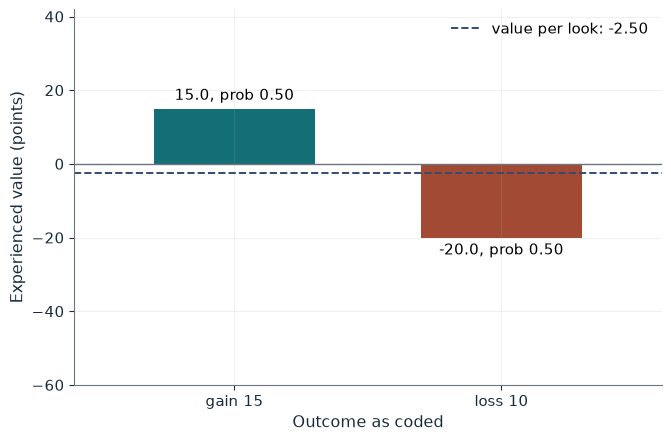

Value per look             -2.50
Two separate looks         -5.00
Two periods aggregated     0.00
Framing that feels better  aggregated

Worked steps:
  1. Per look = 7.5 - 0.5 x 2.0 x 10 = -2.50
  2. Two looks = 2 x -2.50 = -5.00
  3. Aggregated = 7.5 + 2.5 - 0.25 x 2.0 x 20 = 0.00

Separate: 0.5(15) + 0.5[2.0(-10)] = 7.5 - 10.00 = -2.50 per look, -5.00 over two looks. Aggregated: 0.25(30) + 0.50(5) + 0.25[2.0(-20)] = 7.5 + 2.5 - 10.00 = 0.00. The aggregated framing feels better by 5.00 points. The payoffs are identical; only the evaluation boundary changed.


In [4]:
show(loss_picture(lam=2, frame='separate'))

Change one input, `lam`, and hold the others at the book's values:

In [5]:
sweep(loss_picture, 'lam', [1, 1.5, 2, 2.5], {'frame': 'aggregated'}, ['Two separate looks', 'Two periods aggregated', 'Framing that feels better'])

lam | Two separate looks | Two periods aggregated | Framing that feels better
1 | 5.00 | 5.00 | tie
1.5 | 0.00 | 2.50 | aggregated
2 | -5.00 | 0.00 | aggregated
2.5 | -10.00 | -2.50 | aggregated


At lambda 2 two separate looks are worth -5 and the aggregated view 0. With lambda 1 the two framings tie at 5; the more losses hurt, the more aggregation helps.

## 3. Home-bias puzzle

Domestic volatility 22%, foreign 16%, correlation 0.30; the world weight of home equity is 0.10.

$$\sigma_p^2=w^2(0.22)^2+(1-w)^2(0.16)^2+2w(1-w)(0.30)(0.22)(0.16)$$

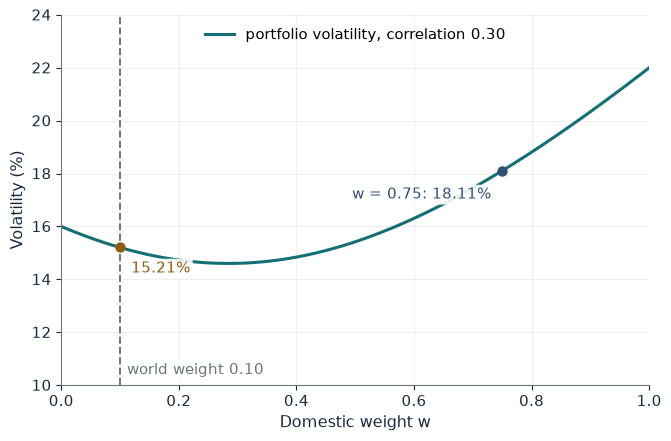

Portfolio variance          0.032785
Volatility                  18.11%
Volatility at world weight  15.21%
Gap versus world weight     2.90 points
Domestic dollars            $150,000

Worked steps:
  1. w^2 x 0.22^2 = 0.75^2 x 0.0484 = 0.027225
  2. (1 - w)^2 x 0.16^2 = 0.25^2 x 0.0256 = 0.0016
  3. 2w(1 - w)(rho)(0.22)(0.16) = 0.00396
  4. Variance = 0.032785, volatility = sqrt(0.032785) = 18.11%
  5. Domestic dollars = 0.75 x 200,000 = $150,000

Variance = 0.75^2(0.0484) + 0.25^2(0.0256) + 2(0.75)(0.25)(0.30)(0.0352) = 0.027225 + 0.0016 + 0.00396 = 0.032785. Volatility is 18.11% against 15.21% at the world weight, a gap of 18.11 - 15.21 = 2.90 points with the same expected return.


In [6]:
show(home_picture(w=0.75, rho=0.30))

Change one input, `w`, and hold the others at the book's values:

In [7]:
sweep(home_picture, 'w', [0.1, 0.4, 0.75, 1.0], {'rho': 0.3}, ['Portfolio variance', 'Volatility', 'Gap versus world weight'])

w | Portfolio variance | Volatility | Gap versus world weight
0.1 | 0.0231208 | 15.21% | 0.00 points
0.4 | 0.0220288 | 14.84% | -0.37 points
0.75 | 0.032785 | 18.11% | 2.90 points
1.0 | 0.0484 | 22.00% | 6.79 points


At w = 0.75 variance is 0.032785 and volatility 18.11%, against 15.21% at the world weight. With equal expected returns that 2.90 point gap is avoidable risk.

## 4. Risk pooling, insurance, and diversification

225 stores, each with a 4% chance of a \$5,000 loss.

$$0.04(0.96)(5{,}000)^2=960{,}000, \qquad 960{,}000\left(0.10+\frac{0.90}{225}\right)=99{,}840$$

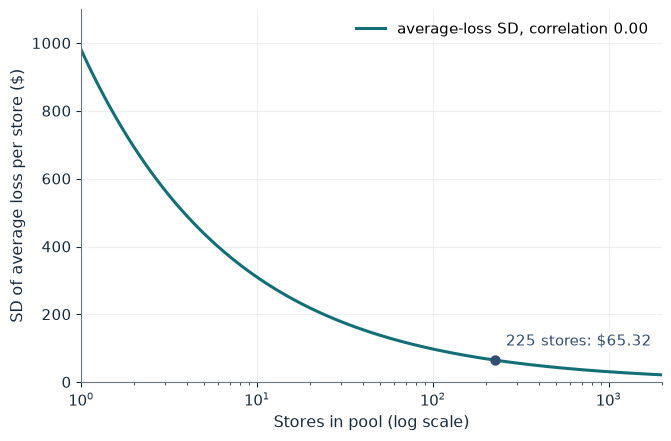

Expected loss per store  $200
Individual SD            $979.80
Average-loss SD          $65.32
Floor as the pool grows  $0.00
Illustrative premium     $240

Worked steps:
  1. Expected loss = 0.04 x 5,000 = 200
  2. Individual variance = 0.04 x 0.96 x 5,000^2 = 960,000
  3. Average variance = 960,000 x (0.00 + 1.00/225) = 4,266.67
  4. Average SD = sqrt(4,266.67) = 65.32
  5. Premium = 200 + 25 + 15 = 240

Expected loss is 0.04(5,000) = 200 and individual variance 0.04(0.96)(5,000)^2 = 960,000, an SD of 979.80. Average-loss variance is 960,000(0.00 + 1.00/225) = 4,266.67, so the SD is 65.32 dollars. Independent losses shrink it by sqrt(225) = 15.00. The premium of 240 is 200 of expected claims plus 25 + 15 for administration and capital.


In [8]:
show(pool_picture(n=225, rho=0.0))

Change one input, `n`, and hold the others at the book's values:

In [9]:
sweep(pool_picture, 'n', [25, 100, 225, 900], {'rho': 0.1}, ['Average-loss SD', 'Floor as the pool grows'])

n | Average-loss SD | Floor as the pool grows
25 | $361.33 | $309.84
100 | $323.48 | $309.84
225 | $315.97 | $309.84
900 | $311.38 | $309.84


Independent losses give an average-loss SD of \$65.32 at 225 stores. With correlation 0.10 it is \$315.97, and quadrupling the pool only brings it to \$311.38, near the \$309.84 floor.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

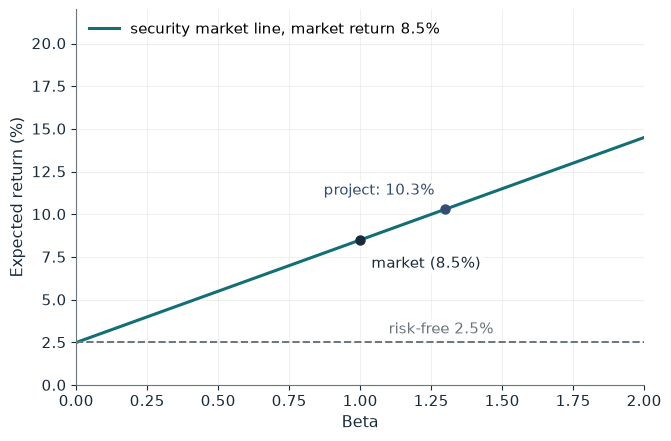

Market premium          6.0%
Required return         10.3%
Benchmark at beta 0.8   7.3%
Change versus beta 0.8  +3.0 points

Worked steps:
  1. Premium = 8.5 - 2.5 = 6.0
  2. E[R] = 2.5 + 1.3 x 6.0 = 2.5 + 7.80 = 10.30%
  3. Benchmark = 2.5 + 0.8 x 6.0 = 7.30%
  4. Change = 10.30 - 7.30 = +3.00 points

The market premium is 8.5 - 2.5 = 6.0%. CAPM gives 2.5 + 1.3 x 6.0 = 2.5 + 7.80 = 10.30%. Against the beta 0.8 benchmark of 7.30% the hurdle is 3.00 points higher.


In [10]:
show(capm_picture(beta=1.3, rm=8.5))

## Practice

**1.** With beta 0.8 and a market return of 10.5%, what is the hurdle rate?

<details><summary>Answer</summary>

2.5 + 0.8 x (10.5 - 2.5) = 2.5 + 6.4 = 8.9%.

</details>

**2.** At lambda = 2.5, what are the separate and aggregated values?

<details><summary>Answer</summary>

Separate: 7.5 - 12.5 = -5 per look, -10 over two looks. Aggregated: 7.5 + 2.5 - 12.5 = -2.5.

</details>

**3.** With 100 independent stores, what is the average-loss SD?

<details><summary>Answer</summary>

979.80 / sqrt(100) = 97.98 dollars.

</details>